## Exploratory Data Analysis

# BIS International Debt Securities, 1962 - 2025

Exploratory Data Analysis (EDA) is the process of examining and visualizing a dataset to understand its structure, patterns and relationships before applying modelling or statistical techniques.

**Steps followed in this project**

1. Data Collection
2. Data Cleaning
3. Data Understanding
4. Univariate Analysis
5. Bivariate Analysis
6. Multivariate Analysis
7. Feature Engineering
8. Outlier Detection
9. Trend and Pattern Analysis
10. Documentation & Reporting (insights, recommendations, limitations)

### Introduction

This dataset is a cleaned and enriched version of the **BIS international debt securities statistics** (table `WS_DEBT_SEC2_PUB`), published by the Bank for International Settlements. Each row is one quarterly observation of debt securities issued on **international markets**, split by issuer country, issuer sector, original maturity and measure.

**Measures**
- `OUTSTANDING` - the stock of debt at the end of the quarter
- `GROSS` - new issues during the quarter
- `NET` - new issues minus repayments (negative = the stock shrank)

**Other important columns**
- Issuer sector: `GOV`, `FIN` (= private/public banks + other financial institutions), `CORP`, `CB`, `INTL` and the total `ALL`
- Maturity: `LT` (long-term), `ST` (short-term), `TOTAL`
- Engineered columns already in the file: QoQ / YoY change, 4Q and 8Q averages, `growth_regime`, `era`, `decade`, crisis flags (`gfc_period`, `covid_period`, `hike_cycle_2022_23`) and country metadata (continent, population, area)

**Objective:** understand how the international debt-securities market grew from 1962 to 2025, who issues the debt, how the sector and maturity mix changed, and how crises (GFC, COVID, 2022-23 rate hikes) changed issuer behaviour.

**Two traps this project deliberately handles**
1. The file mixes real countries with *aggregates* (Developed countries, Emerging markets ...). Adding them together double counts.
2. Sectors and maturities are *nested* (`ALL = GOV + FIN + CORP + CB + INTL`, `TOTAL = LT + ST`). Every analysis therefore filters to one non-overlapping slice.

#### Import the necessary libraries

In [1]:
# remove the warning message
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

#### Import dataset

In [2]:
# change the path if your file is stored somewhere else
import pandas as pd

df = pd.read_csv(r"C:\datascience\dataset\excel\cleaned_dataset.csv", low_memory=False)

# 1. Dataset dimensions, column names, data types, basic structure
print("Dataset Dimensions:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nBasic Structure:")
df.info()


# 2. Top 10 countries with highest total debt securities outstanding
print("\nColumn Names for checking:")
print(df.columns)


Dataset Dimensions: (590285, 36)

Column Names:
Index(['date', 'year', 'quarter_num', 'quarter_label', 'month_name', 'country',
       'country_region', 'country_continent', 'country_subregion',
       'country_population', 'country_area_km2', 'measure', 'measure_code',
       'issuer_sector', 'sector_code', 'original_maturity', 'maturity_code',
       'issue_market', 'value_millions_usd', 'value_billions_usd',
       'value_qoq_abs', 'value_qoq_pct', 'value_yoy_pct', 'value_4q_avg',
       'value_8q_avg', 'is_all_time_high', 'growth_regime', 'era', 'decade',
       'gfc_period', 'covid_period', 'hike_cycle_2022_23',
       'row_completeness_pct', 'data_source', 'retrieved_date',
       'build_timestamp'],
      dtype='object')

Data Types:
date                     object
year                      int64
quarter_num               int64
quarter_label            object
month_name               object
country                  object
country_region           object
country_continent        

#### Display the first 5 rows of the dataset

In [3]:
print(df.head())

         date  year  quarter_num quarter_label month_name  country country_region country_continent country_subregion  country_population  country_area_km2              measure measure_code  \
0  1995-07-01  1995            3       1995-Q3       July  Albania         Europe            Europe  Southeast Europe       2,363,314.000        28,748.000  Amounts outstanding  OUTSTANDING   
1  1995-10-01  1995            4       1995-Q4    October  Albania         Europe            Europe  Southeast Europe       2,363,314.000        28,748.000  Amounts outstanding  OUTSTANDING   
2  1996-01-01  1996            1       1996-Q1    January  Albania         Europe            Europe  Southeast Europe       2,363,314.000        28,748.000  Amounts outstanding  OUTSTANDING   
3  1996-04-01  1996            2       1996-Q2      April  Albania         Europe            Europe  Southeast Europe       2,363,314.000        28,748.000  Amounts outstanding  OUTSTANDING   
4  1996-07-01  1996            3   

#### Display the last 5 rows of the dataset

In [4]:
print(df.tail())

              date  year  quarter_num quarter_label month_name   country country_region country_continent country_subregion  country_population  country_area_km2     measure measure_code  \
590280  1995-07-01  1995            3       1995-Q3       July  Zimbabwe         Africa            Africa   Southern Africa      17,073,087.000       390,757.000  Net issues          NET   
590281  1994-07-01  1994            3       1994-Q3       July  Zimbabwe         Africa            Africa   Southern Africa      17,073,087.000       390,757.000  Net issues          NET   
590282  1994-10-01  1994            4       1994-Q4    October  Zimbabwe         Africa            Africa   Southern Africa      17,073,087.000       390,757.000  Net issues          NET   
590283  1995-04-01  1995            2       1995-Q2      April  Zimbabwe         Africa            Africa   Southern Africa      17,073,087.000       390,757.000  Net issues          NET   
590284  1995-07-01  1995            3       1995-Q

### Data Cleaning

#### 1. Missing values

In [5]:
# Check whether there are any missing values
miss = df.isna().sum()
miss_pct = (miss / len(df) * 100).round(2)
print(pd.DataFrame({'missing': miss, 'missing_%': miss_pct})[miss > 0])

                    missing  missing_%
country_region       108650     18.410
country_continent    108650     18.410
country_subregion    108650     18.410
country_population   108650     18.410
country_area_km2     108650     18.410
value_qoq_abs          7366      1.250
value_qoq_pct          7366      1.250
value_yoy_pct         27596      4.680
value_4q_avg           7366      1.250
value_8q_avg          21119      3.580


Five country-metadata columns are missing in exactly the same **108,650 rows (18.4%)**, so the cause is one thing, not five. The QoQ / YoY / average columns are missing only where a series has not yet built enough history (first quarter, first year, first two years) - that is structural, not an error, so they are left as they are.

In [6]:
# Who is behind the 108,650 missing country_region / continent / population values?
no_meta = df[df['country_region'].isna()]
print(no_meta['country'].value_counts())

country
All countries excluding residents           16544
Developed countries                         14254
Emerging market and developing economies    13516
Developing Latin America and Caribbean      12075
Developing Africa and Middle East           10144
Developing Asia and Pacific                  9873
Developing Europe                            8246
West Indies UK                               6609
Türkiye                                      5231
International organisations                  3809
Chinese Taipei                               3662
Macao SAR                                    2507
Côte d'Ivoire                                1270
Republic of Congo                             580
St Lucia                                      306
Kyrgyz Republic                                24
Name: count, dtype: int64


Two different reasons hide behind the gap:
- **9 aggregates** (Developed countries, EM economies, regional groups, International organisations, West Indies UK ...) are not countries, so they have no continent or population. They are kept but flagged.
- **7 real countries** (Türkiye, Chinese Taipei, Macao SAR, Côte d'Ivoire, Republic of Congo, St Lucia, Kyrgyz Republic) failed the metadata join because of naming differences (e.g. *Türkiye* vs *Turkey*). Region / continent is filled manually. Population and area stay missing for them, which is honest.

In [ ]:
# 1) Aggregates (regional / income groups) are NOT countries -> flag them
AGGREGATES = ['All countries excluding residents', 'Developed countries',
              'Emerging market and developing economies',
              'Developing Latin America and Caribbean', 'Developing Africa and Middle East',
              'Developing Asia and Pacific', 'Developing Europe',
              'West Indies UK', 'International organisations']
df['entity_type'] = np.where(df['country'].isin(AGGREGATES), 'Aggregate', 'Country')

# 2) Real countries whose metadata failed to join (name mismatch) -> fill manually
#    country : (country_region, country_continent)
manual_meta = {
    'Chinese Taipei':    ('Asia',     'Asia'),
    "Côte d'Ivoire":     ('Africa',   'Africa'),
    'Kyrgyz Republic':   ('Asia',     'Asia'),
    'Macao SAR':         ('Asia',     'Asia'),
    'Republic of Congo': ('Africa',   'Africa'),
    'St Lucia':          ('Americas', 'North America'),
    'Türkiye':           ('Europe',   'Europe, Asia'),
}
for c, (reg, cont) in manual_meta.items():
    m = df['country'] == c
    df.loc[m, 'country_region'] = reg
    df.loc[m, 'country_continent'] = cont

print(df['entity_type'].value_counts())
print()
print("Countries still without continent (should only be aggregates):")
print(df[df['country_continent'].isna()]['country'].unique())

Dataset Dimensions: (590285, 36)

Column Names:
['date', 'year', 'quarter_num', 'quarter_label', 'month_name', 'country', 'country_region', 'country_continent', 'country_subregion', 'country_population', 'country_area_km2', 'measure', 'measure_code', 'issuer_sector', 'sector_code', 'original_maturity', 'maturity_code', 'issue_market', 'value_millions_usd', 'value_billions_usd', 'value_qoq_abs', 'value_qoq_pct', 'value_yoy_pct', 'value_4q_avg', 'value_8q_avg', 'is_all_time_high', 'growth_regime', 'era', 'decade', 'gfc_period', 'covid_period', 'hike_cycle_2022_23', 'row_completeness_pct', 'data_source', 'retrieved_date', 'build_timestamp']

Data Types:
date                     object
year                      int64
quarter_num               int64
quarter_label            object
month_name               object
country                  object
country_region           object
country_continent        object
country_subregion        object
country_population      float64
country_area_km2     

#### 2. Data types and constant columns

In [8]:
# Transform date to datetime
df['date'] = pd.to_datetime(df['date'])

# Constant columns carry no information -> check & drop
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns:", const_cols)
df.drop(columns=const_cols, inplace=True)

# Text columns -> category (saves memory & speeds up group-bys)
for c in ['country','country_region','country_continent','country_subregion','measure_code',
          'sector_code','maturity_code','era','decade','growth_regime','entity_type']:
    df[c] = df[c].astype('category')
print()
print("Remaining columns:", df.shape[1])

Constant columns: ['issue_market', 'row_completeness_pct', 'data_source', 'retrieved_date', 'build_timestamp']

Remaining columns: 32


#### 3. Duplicates

In [9]:
# Check for duplicate rows (full row and on the business key)
KEY = ['date', 'country', 'measure_code', 'sector_code', 'maturity_code']
print("Fully duplicated rows      :", df.duplicated().sum())
print("Duplicates on business key :", df.duplicated(KEY).sum())

Fully duplicated rows      : 0
Duplicates on business key : 0


#### 4. Sanity checks

In [10]:
# Sanity checks
# 1. billions == millions / 1000 ?
print("Unit mismatch rows (>0.001 bn):", ((df['value_billions_usd'] - df['value_millions_usd']/1000).abs() > 0.001).sum())

# 2. negative values are only valid for NET issues (repayments > new issues)
print("\nShare of negative values by measure:")
print(df.groupby('measure_code')['value_billions_usd'].apply(lambda s: (s < 0).mean()).round(3))

# 3. quarter_label really matches the date ?
chk = df['date'].dt.year.astype(str) + '-Q' + df['date'].dt.quarter.astype(str)
print("\nquarter_label mismatches:", (chk != df['quarter_label']).sum())

# 4. Date range
print("\nDate range:", df['date'].min().date(), "->", df['date'].max().date())

Unit mismatch rows (>0.001 bn): 0

Share of negative values by measure:
measure_code
GROSS         0.000
NET           0.363
OUTSTANDING   0.000
Name: value_billions_usd, dtype: float64

quarter_label mismatches: 0

Date range: 1962-10-01 -> 2025-10-01


Negative values exist only for `NET` (about 36% of net-issue rows), which is valid: repayments exceeded new issues. `OUTSTANDING` and `GROSS` are never negative, units are consistent and there are no duplicates.

#### 5. Verify the nested hierarchy (double-counting check)

In [11]:
# The BIS hierarchy is NESTED. If we add everything up we double count!
# Verify: ALL = GOV + FIN + CORP + CB + INTL   and   TOTAL = LT + ST   (country level, latest quarter)
ctry_ = df[df['entity_type'] == 'Country']
snap = ctry_[(ctry_['measure_code'] == 'OUTSTANDING') & (ctry_['maturity_code'] == 'TOTAL')
             & (ctry_['date'] == df['date'].max())]
tot = snap.groupby('sector_code', observed=True)['value_billions_usd'].sum()
print(tot.round(1))
print("\nALL                      :", round(tot['ALL'], 1))
print("GOV+FIN+CORP+CB+INTL     :", round(tot[['GOV','FIN','CORP','CB','INTL']].sum(), 1))
print("FIN vs BANK+OFI (pri+pub):", round(tot['FIN'], 1), "vs", round(tot[['BANK_PRI','BANK_PUB','FIN_PRI','FIN_PUB']].sum(), 1))

sector_code
ALL        30,603.800
BANK_PRI    8,186.300
BANK_PUB      405.100
CB             26.600
CORP        4,808.600
FIN        22,703.100
FIN_PRI    13,141.600
FIN_PUB       943.500
GOV         3,089.300
INTL            2.900
Name: value_billions_usd, dtype: float64

ALL                      : 30603.8
GOV+FIN+CORP+CB+INTL     : 30630.4
FIN vs BANK+OFI (pri+pub): 22703.1 vs 22676.5


`ALL` (30,603.8 bn) matches the sum of its five sectors (30,630.4 bn) within **0.09%** and `FIN` matches banks + other financials within 0.1%, so the hierarchy holds. This is why analysis below always uses **one level at a time**.

#### 6. Create the analysis frames

In [12]:
LATEST = df['date'].max()
ctry = df[df['entity_type'] == 'Country'].copy()          # real countries only
aggs = df[df['entity_type'] == 'Aggregate'].copy()        # groups (Developed, EM ...)

# Headline slice = one number per country per quarter, no double counting
out_all = ctry[(ctry['measure_code'] == 'OUTSTANDING') &
               (ctry['sector_code'] == 'ALL') &
               (ctry['maturity_code'] == 'TOTAL')].copy()
out_all = out_all.sort_values(['country', 'date'])

print("Country-level rows        :", len(ctry))
print("Headline (out_all) rows   :", len(out_all))
print("Countries in headline     :", out_all['country'].nunique())
print("Latest quarter            :", LATEST.date())

Country-level rows        : 495215
Headline (out_all) rows   : 20837
Countries in headline     : 162
Latest quarter            : 2025-10-01


- `ctry` - real countries only (no aggregates)
- `aggs` - BIS aggregates only
- `out_all` - the **headline slice**: `OUTSTANDING` x `ALL` sectors x `TOTAL` maturity, one row per country per quarter

### Data Understanding

In [13]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 590285 entries, 0 to 590284
Data columns (total 32 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   date                590285 non-null  datetime64[us]
 1   year                590285 non-null  int64         
 2   quarter_num         590285 non-null  int64         
 3   quarter_label       590285 non-null  str           
 4   month_name          590285 non-null  str           
 5   country             590285 non-null  category      
 6   country_region      495215 non-null  category      
 7   country_continent   495215 non-null  category      
 8   country_subregion   481635 non-null  category      
 9   country_population  481635 non-null  float64       
 10  country_area_km2    481635 non-null  float64       
 11  measure             590285 non-null  str           
 12  measure_code        590285 non-null  category      
 13  issuer_sector       590285 non-null  str

In [14]:
# Summary statistics of numerical columns
print(df.describe().T)

                         count                        mean                  min                  25%                  50%                  75%                  max             std
date                    590285  2004-06-10 15:10:25.274232  1962-10-01 00:00:00  1994-07-01 00:00:00  2006-04-01 00:00:00  2016-07-01 00:00:00  2025-10-01 00:00:00             NaN
year               590,285.000                   2,004.066            1,962.000            1,994.000            2,006.000            2,016.000            2,025.000          14.352
quarter_num        590,285.000                       2.511                1.000                2.000                3.000                4.000                4.000           1.118
country_population 481,635.000              75,476,921.966           11,680.000        5,490,000.000       11,825,551.000       58,927,633.000    1,417,492,000.000 220,574,740.094
country_area_km2   481,635.000               1,383,013.479                2.020           41,865.000

The maximum outstanding value is 27.4 trillion USD (an aggregate) while the median row is under 1 bn, so the data is extremely right-skewed. `value_yoy_pct` reaches +1,969,300% and -1,456,400%: growth rates measured on almost-zero bases. This is handled in the outlier section.

In [ ]:
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include=['category','object','string']).columns.tolist()
print("Numerical   (%d):" % len(num_cols), num_cols)
print()
print("Categorical (%d):" % len(cat_cols), cat_cols)
print()
print("Unique countries      :", df.loc[df.entity_type=='Country','country'].nunique())
print("Unique sectors        :", df['sector_code'].nunique())
print("Unique quarters       :", df['date'].nunique())

Numerical   (15): ['year', 'quarter_num', 'country_population', 'country_area_km2', 'value_millions_usd', 'value_billions_usd', 'value_qoq_abs', 'value_qoq_pct', 'value_yoy_pct', 'value_4q_avg', 'value_8q_avg', 'is_all_time_high', 'gfc_period', 'covid_period', 'hike_cycle_2022_23']

Categorical (16): ['quarter_label', 'month_name', 'country', 'country_region', 'country_continent', 'country_subregion', 'measure', 'measure_code', 'issuer_sector', 'sector_code', 'original_maturity', 'maturity_code', 'growth_regime', 'era', 'decade', 'entity_type']

Unique countries      : 162
Unique sectors        : 10
Unique quarters       : 253


Questions

1. What are the dimensions, column names, data types, and basic structure of the dataset?
2. What are the top 10 countries with the highest total debt securities outstanding?
3. What is the average debt securities outstanding for each country?
4. Which countries have the highest average debt securities outstanding?
5. What are the top 10 countries with the highest number of records in the dataset?
6. How many records belong to each year, and what percentage of the dataset does each year represent?
7. What is the average debt securities outstanding for each year?
8. Which years have an average debt securities outstanding greater than the overall average?
9. Which countries have a total debt securities outstanding greater than the overall average total debt securities outstanding across countries?
10. For each year, which country has the highest debt securities outstanding?
11. What are the mean, median, standard deviation, minimum, and maximum values of the debt securities outstanding column?
12. What are the 25th, 50th, and 75th percentiles of debt securities outstanding?
13. What percentage of records have debt securities outstanding greater than the overall average?
14. How many records contain missing values in each column, and what percentage of the dataset does each represent?
15. Which countries have missing debt securities outstanding values?
16. What are the top 10 countries with the largest increase in debt securities outstanding between the earliest and latest available years?
17. What are the top 10 countries with the largest decrease in total debt securities outstanding between the earliest and latest available years?
18. For each country, what is the minimum, maximum, mean, and standard deviation of debt securities outstanding?
19. Create a pivot table showing the average debt securities outstanding for each country and year.
20. Create a pivot table showing the total debt securities outstanding for each year and country.
21. Which countries have an average debt securities outstanding greater than 10% above the overall average?
22. What percentage of the total debt securities outstanding is contributed by each of the top 10 countries?
23. Create a line graph showing the change in total debt securities outstanding over the years.
24. Create a bar graph showing the top 10 countries with the highest total debt securities outstanding.
25. Create a histogram showing the distribution of debt securities outstanding.
26. Create a box plot to identify the distribution and outliers in debt securities outstanding.
27. Create a scatter plot showing the relationship between year and debt securities outstanding.
28. Create a pie chart showing the percentage share of the top 5 countries in total debt securities outstanding.
29. Find the country with the highest year-over-year increase in debt securities outstanding.
30. Find the top 10 countries with the largest percentage increase in debt securities outstanding from their first recorded year to their last recorded year.

1. Dataset dimensions, column names, data types, basic structure


In [8]:
print("Dataset Dimensions:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nBasic Structure:")
df.info()

Dataset Dimensions:
(590285, 36)

Column Names:
Index(['date', 'year', 'quarter_num', 'quarter_label', 'month_name', 'country',
       'country_region', 'country_continent', 'country_subregion',
       'country_population', 'country_area_km2', 'measure', 'measure_code',
       'issuer_sector', 'sector_code', 'original_maturity', 'maturity_code',
       'issue_market', 'value_millions_usd', 'value_billions_usd',
       'value_qoq_abs', 'value_qoq_pct', 'value_yoy_pct', 'value_4q_avg',
       'value_8q_avg', 'is_all_time_high', 'growth_regime', 'era', 'decade',
       'gfc_period', 'covid_period', 'hike_cycle_2022_23',
       'row_completeness_pct', 'data_source', 'retrieved_date',
       'build_timestamp'],
      dtype='object')

Data Types:
date                     object
year                      int64
quarter_num               int64
quarter_label            object
month_name               object
country                  object
country_region           object
country_continent        

2.What are the top 10 countries with the highest total debt securities outstanding?

In [11]:
print(df.columns)
total_debt = df.groupby('country')['year'].sum()

top_10 = total_debt.sort_values(ascending=False).head(10)

print(top_10)

Index(['date', 'year', 'quarter_num', 'quarter_label', 'month_name', 'country',
       'country_region', 'country_continent', 'country_subregion',
       'country_population', 'country_area_km2', 'measure', 'measure_code',
       'issuer_sector', 'sector_code', 'original_maturity', 'maturity_code',
       'issue_market', 'value_millions_usd', 'value_billions_usd',
       'value_qoq_abs', 'value_qoq_pct', 'value_yoy_pct', 'value_4q_avg',
       'value_8q_avg', 'is_all_time_high', 'growth_regime', 'era', 'decade',
       'gfc_period', 'covid_period', 'hike_cycle_2022_23',
       'row_completeness_pct', 'data_source', 'retrieved_date',
       'build_timestamp'],
      dtype='object')
country
All countries excluding residents           33069306
Developed countries                         28500794
Emerging market and developing economies    27030783
Developing Latin America and Caribbean      24148439
France                                      22892388
Sweden                               

3. Average debt securities outstanding for each country

In [14]:
average_debt = df.groupby('country')['value_millions_usd'].mean()

print("Average Debt Securities for Each Country:")
print(average_debt.sort_values(ascending=False))


Average Debt Securities for Each Country:
country
Developed countries                  793355.130981
All countries excluding residents    543782.715123
United Kingdom                       175779.311849
International organisations          167215.482016
United States                        132680.784629
                                         ...      
Djibouti                                 17.333333
Myanmar                                   9.893333
Zimbabwe                                  8.181818
Haiti                                     7.761194
Nicaragua                                 4.913043
Name: value_millions_usd, Length: 171, dtype: float64


4. Which countries have the highest average debt securities outstanding?

In [15]:
average_debt = df.groupby('country')['value_millions_usd'].mean()

highest_average = average_debt.sort_values(ascending=False)

print("Countries with Highest Average Debt Securities:")
print(highest_average)

Countries with Highest Average Debt Securities:
country
Developed countries                  793355.130981
All countries excluding residents    543782.715123
United Kingdom                       175779.311849
International organisations          167215.482016
United States                        132680.784629
                                         ...      
Djibouti                                 17.333333
Myanmar                                   9.893333
Zimbabwe                                  8.181818
Haiti                                     7.761194
Nicaragua                                 4.913043
Name: value_millions_usd, Length: 171, dtype: float64


5. Top 10 countries with the highest number of records in the dataset

In [16]:
country_records = df['country'].value_counts().head(10)

print("Top 10 Countries with Highest Number of Records:")
print(country_records)

Top 10 Countries with Highest Number of Records:
All countries excluding residents           16544
Developed countries                         14254
Emerging market and developing economies    13516
Developing Latin America and Caribbean      12075
France                                      11438
Sweden                                      11436
Australia                                   11338
Netherlands                                 11183
Canada                                      11065
United States                               11060
Name: country, dtype: int64


6. Number of records belonging to each year and percentage of the dataset

In [17]:
year_records = df['year'].value_counts().sort_index()

year_percentage = (year_records / len(df)) * 100

year_summary = pd.DataFrame({
    'Number_of_Records': year_records,
    'Percentage': year_percentage.round(2)
})

print("Records and Percentage for Each Year:")
print(year_summary)

Records and Percentage for Each Year:
      Number_of_Records  Percentage
1962                 36        0.01
1963                 48        0.01
1964                 48        0.01
1965                 48        0.01
1966                464        0.08
...                 ...         ...
2021              16115        2.73
2022              15774        2.67
2023              15856        2.69
2024              16206        2.75
2025              16643        2.82

[64 rows x 2 columns]


7. What is the average debt securities outstanding for each year?

In [18]:
yearly_average = df.groupby('year')['value_millions_usd'].mean()

print("Average Debt Securities for Each Year:")
print(yearly_average)

Average Debt Securities for Each Year:
year
1962         6.000000
1963         6.000000
1964         6.000000
1965         6.000000
1966        24.644397
            ...      
2021    107747.982066
2022    105929.320844
2023    110331.973385
2024    114672.121313
2025    124401.309860
Name: value_millions_usd, Length: 64, dtype: float64


8. Which years have an average debt securities outstanding greater than the overall average?

In [ ]:
yearly_average = df.groupby('year')['value_millions_usd'].mean()

overall_average = df['value_millions_usd'].mean()

print("Overall Average:", overall_average)

print("\nYears with Average Greater than Overall Average:")
print(yearly_average[yearly_average > overall_average])

Overall Average: 59190.836004641824

Years with Average Greater than Overall Average:
year
2006     69659.666403
2007     86434.558809
2008     99738.713060
2009    100911.267730
2010     98069.284455
2011     98792.845122
2012     94184.738042
2013     93432.356831
2014     93154.820744
2015     87387.937875
2016     89610.505079
2017     92382.867152
2018     99836.951320
2019     98665.150432
2020    101784.177531
2021    107747.982066
2022    105929.320844
2023    110331.973385
2024    114672.121313
2025    124401.309860
Name: value_millions_usd, dtype: float64


9. Which countries have a total debt securities outstanding greater than the overall average total debt securities outstanding across countries?

In [20]:
country_total = df.groupby('country')['value_millions_usd'].sum()

overall_average_total = country_total.mean()

print("Overall Average Total Debt:", overall_average_total)

print("\nCountries Above Overall Average Total Debt:")
print(country_total[country_total > overall_average_total].sort_values(ascending=False))

Overall Average Total Debt: 204324342.87134504

Countries Above Overall Average Total Debt:
country
Developed countries                         1.130848e+10
All countries excluding residents           8.996341e+09
United Kingdom                              1.906327e+09
United States                               1.467449e+09
Netherlands                                 1.163640e+09
Cayman Islands                              9.871585e+08
Emerging market and developing economies    8.964862e+08
France                                      7.870985e+08
Germany                                     7.634875e+08
International organisations                 6.369238e+08
Ireland                                     5.650365e+08
Italy                                       4.423346e+08
Canada                                      4.355852e+08
Luxembourg                                  4.025103e+08
Developing Latin America and Caribbean      3.936642e+08
Australia                                   3

10. For each year, which country has the highest debt securities outstanding?

In [21]:
year_country_total = df.groupby(['year', 'country'])['value_millions_usd'].sum()

highest_country = year_country_total.groupby(level='year').idxmax()

result = year_country_total.loc[highest_country.values]

print("Country with Highest Debt Securities for Each Year:")
print(result)

Country with Highest Debt Securities for Each Year:
year  country                          
1962  All countries excluding residents           72.0
1963  All countries excluding residents           96.0
1964  All countries excluding residents           96.0
1965  All countries excluding residents           96.0
1966  Developed countries                       3596.0
                                              ...     
2021  Developed countries                  548341920.0
2022  Developed countries                  526521926.0
2023  Developed countries                  551204247.0
2024  Developed countries                  583936449.0
2025  Developed countries                  649909505.0
Name: value_millions_usd, Length: 64, dtype: float64


11. Mean, median, standard deviation, minimum and maximum values

In [22]:
debt = df['value_millions_usd']

print("Mean:", debt.mean())
print("Median:", debt.median())
print("Standard Deviation:", debt.std())
print("Minimum:", debt.min())
print("Maximum:", debt.max())

Mean: 59190.836004641824
Median: 850.0
Standard Deviation: 598060.4771809686
Minimum: -180854.0
Maximum: 27398838.0


12. What are the 25th, 50th, and 75th percentiles of debt securities outstanding?

In [4]:
percentiles = df['value_millions_usd'].quantile([0.25, 0.50, 0.75])

print("25th, 50th, and 75th Percentiles:")
print(percentiles)

25th, 50th, and 75th Percentiles:
0.25      94.0
0.50     850.0
0.75    6316.0
Name: value_millions_usd, dtype: float64


13. What percentage of records have debt securities outstanding greater than the overall average?

In [3]:
overall_average = df['value_millions_usd'].mean()

count_above_average = (df['value_millions_usd'] > overall_average).sum()

percentage = (count_above_average / df['value_millions_usd'].count()) * 100

print("Overall Average:", overall_average)
print("Records Above Average:", count_above_average)
print("Percentage:", round(percentage, 2), "%")

Overall Average: 59190.836004641824
Records Above Average: 46187
Percentage: 7.82 %


14. How many records contain missing values in each column, and what percentage of the dataset does each represent?

In [5]:
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Percentage': missing_percentage.round(2)
})

print(missing_summary[missing_summary['Missing_Count'] > 0])

                    Missing_Count  Missing_Percentage
country_region             108650               18.41
country_continent          108650               18.41
country_subregion          108650               18.41
country_population         108650               18.41
country_area_km2           108650               18.41
value_qoq_abs                7366                1.25
value_qoq_pct                7366                1.25
value_yoy_pct               27596                4.68
value_4q_avg                 7366                1.25
value_8q_avg                21119                3.58


15. Which countries have missing debt securities outstanding values?

In [3]:
missing_countries = df.loc[
    df['value_millions_usd'].isnull(), 'country'
].unique()

print("Countries with Missing Debt Values:")
print(missing_countries)

Countries with Missing Debt Values:
[]


16. Top 10 countries with the largest increase in debt securities outstanding between the earliest and latest available years

In [4]:
earliest_year = df['year'].min()
latest_year = df['year'].max()

yearly_country_debt = df[
    df['year'].isin([earliest_year, latest_year])
].groupby(['country', 'year'])['value_millions_usd'].sum().unstack()

if earliest_year in yearly_country_debt.columns and latest_year in yearly_country_debt.columns:

    yearly_country_debt = yearly_country_debt.dropna(
        subset=[earliest_year, latest_year]
    )

    yearly_country_debt['Increase'] = (
        yearly_country_debt[latest_year] -
        yearly_country_debt[earliest_year]
    )

    top_10_increase = yearly_country_debt.sort_values(
        by='Increase', ascending=False
    ).head(10)

    print("Earliest Year:", earliest_year)
    print("Latest Year:", latest_year)
    print("\nTop 10 Countries with Largest Increase:")
    print(top_10_increase[['Increase']])

else:
    print("Required year data is not available.")

Earliest Year: 1962
Latest Year: 2025

Top 10 Countries with Largest Increase:
year                                  Increase
country                                       
Developed countries                649909433.0
All countries excluding residents  526130523.0
Iceland                               374348.0


17. Top 10 countries with the largest decrease in total debt securities outstanding

In [5]:
earliest_year = df['year'].min()
latest_year = df['year'].max()

yearly_debt = df[
    df['year'].isin([earliest_year, latest_year])
].groupby(['country', 'year'])['value_millions_usd'].sum().unstack()

yearly_debt = yearly_debt.dropna(
    subset=[earliest_year, latest_year]
)

yearly_debt['Decrease'] = (
    yearly_debt[earliest_year] - yearly_debt[latest_year]
)

top_10_decrease = yearly_debt.sort_values(
    by='Decrease', ascending=False
).head(10)

print("Earliest Year:", earliest_year)
print("Latest Year:", latest_year)
print("\nTop 10 Countries with Largest Decrease:")
print(top_10_decrease[['Decrease']])

Earliest Year: 1962
Latest Year: 2025

Top 10 Countries with Largest Decrease:
year                                  Decrease
country                                       
Iceland                              -374348.0
All countries excluding residents -526130523.0
Developed countries               -649909433.0


18. Minimum, maximum, mean, and standard deviation for each country

In [6]:
country_statistics = df.groupby('country')['value_millions_usd'].agg(
    ['min', 'max', 'mean', 'std']
)

print("Debt Securities Statistics for Each Country:")
print(country_statistics)

Debt Securities Statistics for Each Country:
                                        min         max           mean  \
country                                                                  
Albania                             -1163.0      4419.0     901.687943   
Algeria                              -500.0      1597.0     356.475504   
All countries excluding residents -176387.0  22955735.0  543782.715123   
Angola                              -1000.0     15567.0    3915.229947   
Argentina                          -29907.0    122609.0    7456.676487   
...                                     ...         ...            ...   
Venezuela                           -7091.0     56845.0    5122.063741   
Vietnam                             -1176.0      4526.0     870.920341   
West Indies UK                     -19993.0    427044.0   15161.227871   
Zambia                              -1000.0      4250.0    2931.451613   
Zimbabwe                              -10.0        20.0       8.181

19. Pivot table showing average debt securities outstanding for each country and year

In [7]:
average_pivot = pd.pivot_table(
    df,
    values='value_millions_usd',
    index='country',
    columns='year',
    aggfunc='mean'
)

print("Average Debt Securities by Country and Year:")
print(average_pivot)

Average Debt Securities by Country and Year:
year                               1962  1963  1964  1965       1966  \
country                                                                
Albania                             NaN   NaN   NaN   NaN        NaN   
Algeria                             NaN   NaN   NaN   NaN        NaN   
All countries excluding residents   6.0   6.0   6.0   6.0  30.919643   
Angola                              NaN   NaN   NaN   NaN        NaN   
Argentina                           NaN   NaN   NaN   NaN        NaN   
...                                 ...   ...   ...   ...        ...   
Venezuela                           NaN   NaN   NaN   NaN        NaN   
Vietnam                             NaN   NaN   NaN   NaN        NaN   
West Indies UK                      NaN   NaN   NaN   NaN        NaN   
Zambia                              NaN   NaN   NaN   NaN        NaN   
Zimbabwe                            NaN   NaN   NaN   NaN        NaN   

year              

20. Create a pivot table showing the total debt securities outstanding for each year and country.

In [8]:
total_pivot = pd.pivot_table(
    df,
    values='value_millions_usd',
    index='year',
    columns='country',
    aggfunc='sum'
)

print(total_pivot)

country  Albania  Algeria  All countries excluding residents    Angola  \
year                                                                     
1962         NaN      NaN                               72.0       NaN   
1963         NaN      NaN                               96.0       NaN   
1964         NaN      NaN                               96.0       NaN   
1965         NaN      NaN                               96.0       NaN   
1966         NaN      NaN                             3463.0       NaN   
...          ...      ...                                ...       ...   
2021     43664.0      NaN                        438606867.0  128000.0   
2022     42692.0      NaN                        423203354.0  187672.0   
2023     56992.0      NaN                        444841327.0  179348.0   
2024     54140.0      NaN                        472219741.0  194268.0   
2025     62404.0      NaN                        526130595.0  257008.0   

country  Argentina  Armenia    Aruba 

21. Which countries have an average debt securities outstanding greater than 10% above the overall average?

In [9]:
country_average = df.groupby('country')['value_millions_usd'].mean()

overall_average = df['value_millions_usd'].mean()

threshold = overall_average * 1.10

result = country_average[country_average > threshold]

print("Overall Average:", overall_average)
print("\nCountries Above 10% of Overall Average:")
print(result.sort_values(ascending=False))

Overall Average: 59190.836004641824

Countries Above 10% of Overall Average:
country
Developed countries                         793355.130981
All countries excluding residents           543782.715123
United Kingdom                              175779.311849
International organisations                 167215.482016
United States                               132680.784629
Cayman Islands                              117351.220399
Netherlands                                 104054.364661
Germany                                      72122.379275
France                                       68814.347701
Emerging market and developing economies     66327.773380
Name: value_millions_usd, dtype: float64


22. What percentage of total debt securities outstanding is contributed by each of the top 10 countries?

In [10]:
country_total = df.groupby('country')['value_millions_usd'].sum()

top_10 = country_total.sort_values(ascending=False).head(10)

percentage = (top_10 / country_total.sum()) * 100

result = pd.DataFrame({
    'Total_Debt_Millions_USD': top_10,
    'Percentage_Share': percentage.round(2)
})

print(result)

                                          Total_Debt_Millions_USD  \
country                                                             
Developed countries                                  1.130848e+10   
All countries excluding residents                    8.996341e+09   
United Kingdom                                       1.906327e+09   
United States                                        1.467449e+09   
Netherlands                                          1.163640e+09   
Cayman Islands                                       9.871585e+08   
Emerging market and developing economies             8.964862e+08   
France                                               7.870985e+08   
Germany                                              7.634875e+08   
International organisations                          6.369238e+08   

                                          Percentage_Share  
country                                                     
Developed countries                              

23. Create a line graph showing the change in total debt securities outstanding over the years.


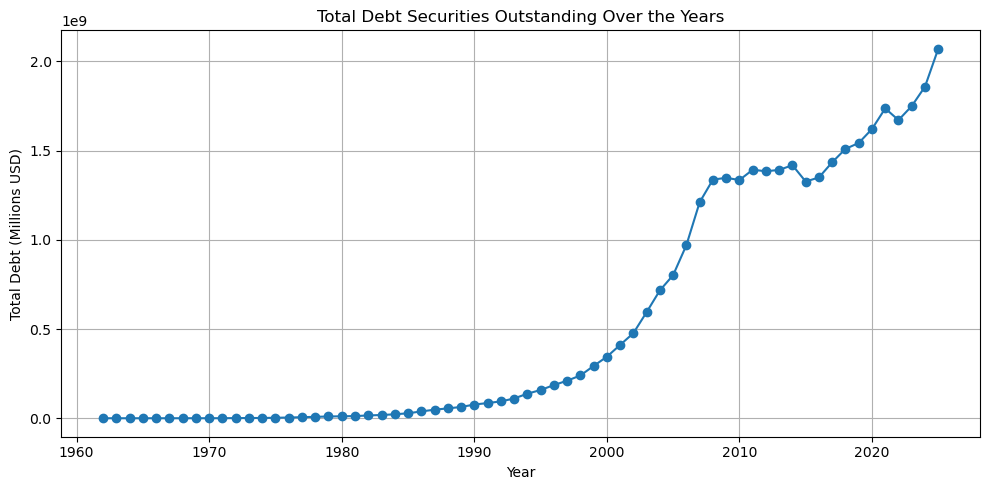

In [11]:
import matplotlib.pyplot as plt

yearly_total = df.groupby('year')['value_millions_usd'].sum()

plt.figure(figsize=(10, 5))
plt.plot(yearly_total.index, yearly_total.values, marker='o')

plt.title('Total Debt Securities Outstanding Over the Years')
plt.xlabel('Year')
plt.ylabel('Total Debt (Millions USD)')
plt.grid(True)
plt.tight_layout()
plt.show()

24. Create a bar graph showing the top 10 countries with the highest total debt securities outstanding.

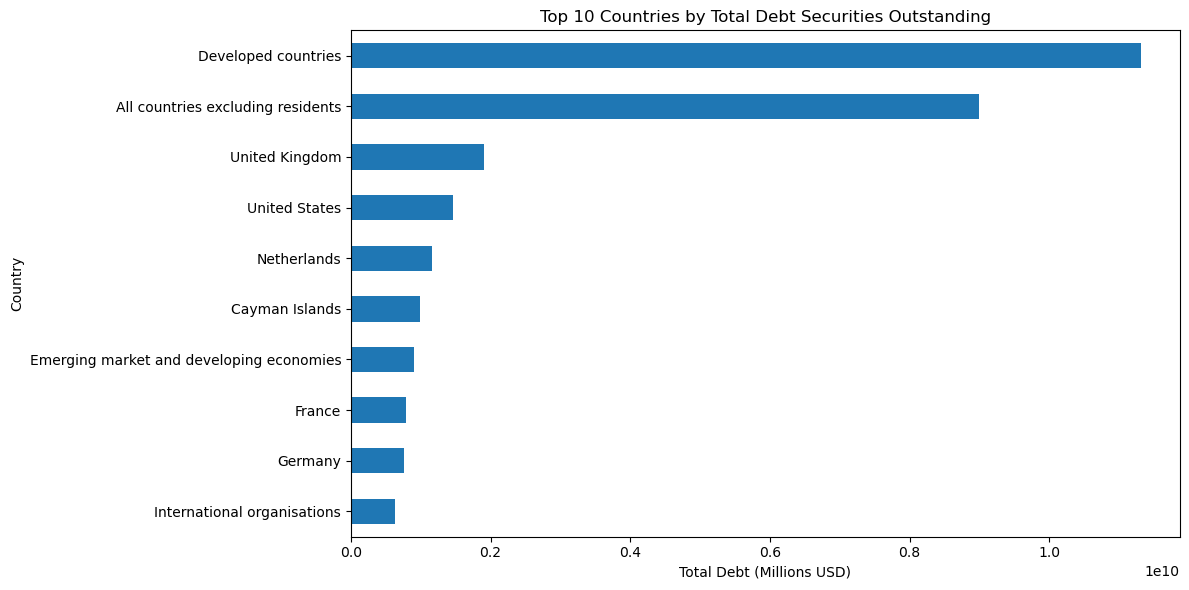

In [12]:
country_total = df.groupby('country')['value_millions_usd'].sum()

top_10 = country_total.sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
top_10.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Total Debt Securities Outstanding')
plt.xlabel('Total Debt (Millions USD)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

25. Create a histogram showing the distribution of debt securities outstanding.

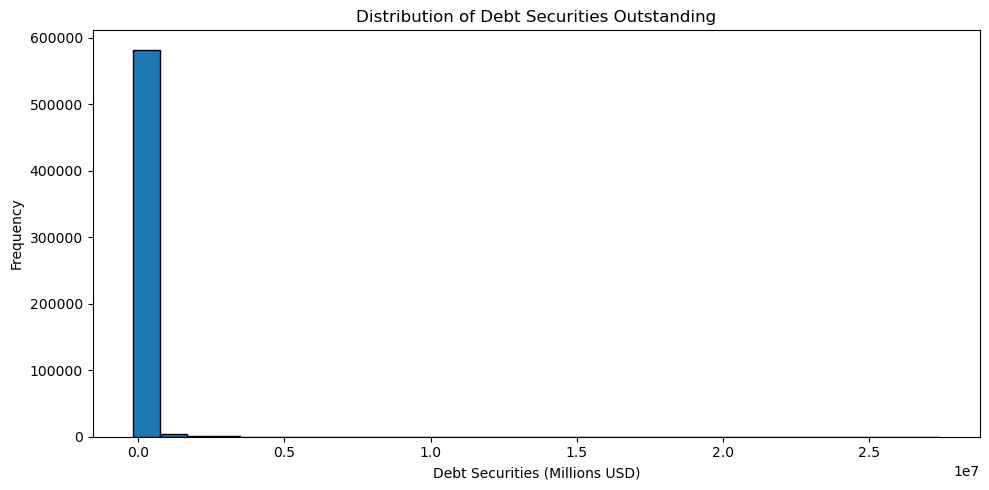

In [13]:
debt = df['value_millions_usd'].dropna()

plt.figure(figsize=(10, 5))
plt.hist(debt, bins=30, edgecolor='black')

plt.title('Distribution of Debt Securities Outstanding')
plt.xlabel('Debt Securities (Millions USD)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

26. Create a box plot to identify the distribution and outliers in debt securities outstanding.

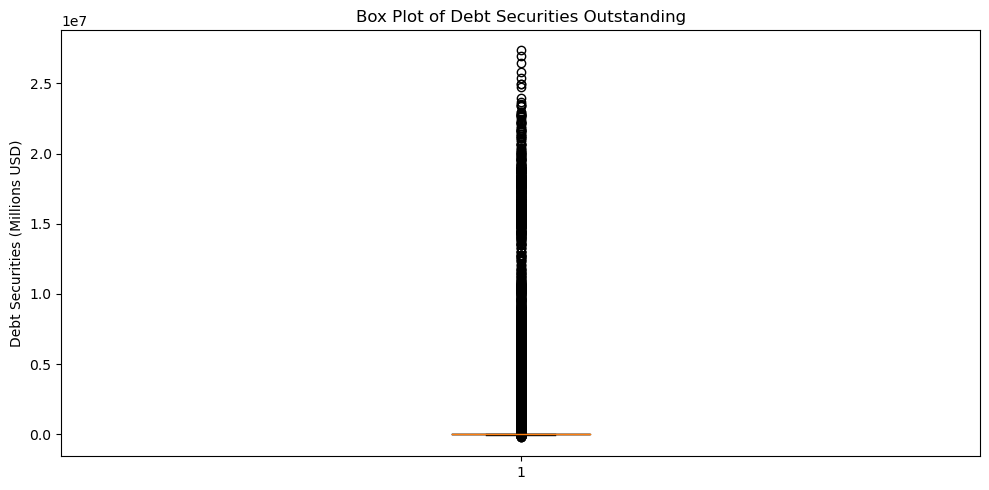

In [14]:
debt = df['value_millions_usd'].dropna()

plt.figure(figsize=(10, 5))
plt.boxplot(debt)

plt.title('Box Plot of Debt Securities Outstanding')
plt.ylabel('Debt Securities (Millions USD)')
plt.tight_layout()
plt.show()

27. Create a scatter plot showing the relationship between year and debt securities outstanding.

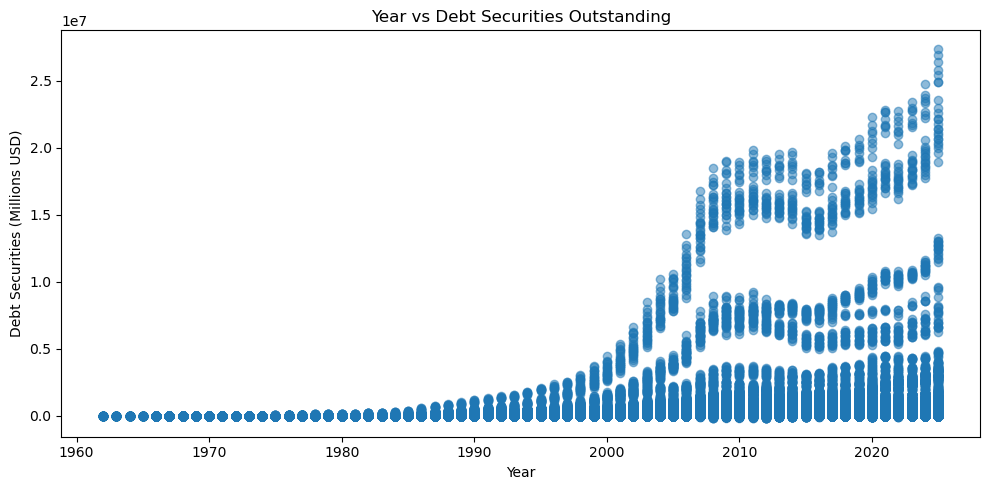

In [15]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df['year'],
    df['value_millions_usd'],
    alpha=0.5
)

plt.title('Year vs Debt Securities Outstanding')
plt.xlabel('Year')
plt.ylabel('Debt Securities (Millions USD)')
plt.tight_layout()
plt.show()

28. Create a pie chart showing the percentage share of the top 5 countries in total debt securities outstanding.

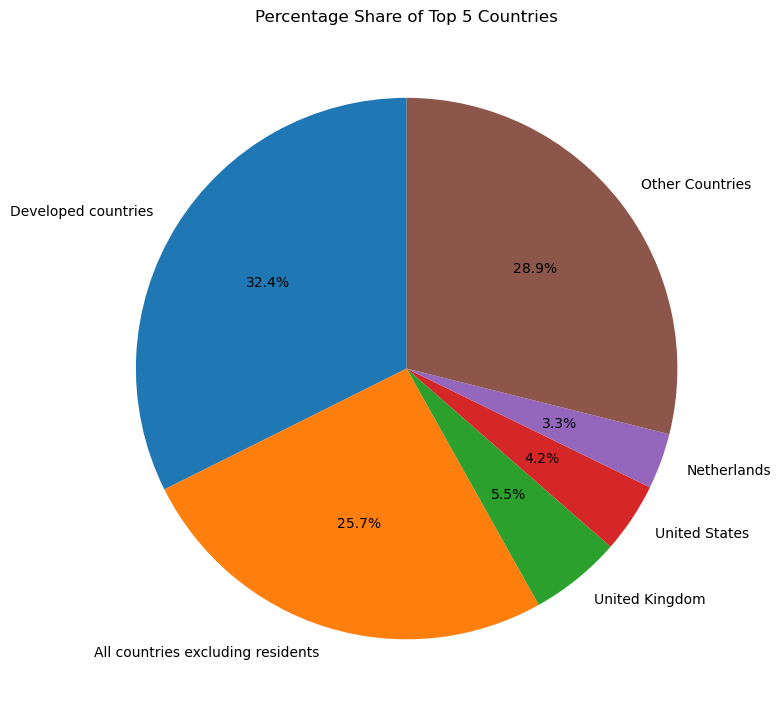

In [16]:
country_total = df.groupby('country')['value_millions_usd'].sum()

top_5 = country_total.sort_values(ascending=False).head(5)

other_total = country_total.sum() - top_5.sum()

pie_data = pd.concat([
    top_5,
    pd.Series({'Other Countries': other_total})
])

plt.figure(figsize=(8, 8))

plt.pie(
    pie_data,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Share of Top 5 Countries')
plt.tight_layout()
plt.show()

29. Find the country with the highest year-over-year increase in debt securities outstanding.

In [17]:
yearly_country = df.groupby(
    ['country', 'year']
)['value_millions_usd'].sum().reset_index()

yearly_country = yearly_country.sort_values(['country', 'year'])

yearly_country['Increase'] = yearly_country.groupby(
    'country'
)['value_millions_usd'].diff()

highest_increase = yearly_country.loc[
    yearly_country['Increase'].idxmax()
]

print("Country:", highest_increase['country'])
print("Year:", highest_increase['year'])
print("Increase in Debt (Millions USD):", highest_increase['Increase'])

Country: Developed countries
Year: 2007
Increase in Debt (Millions USD): 83246409.0


30. Find the top 10 countries with the largest percentage increase from their first recorded year to their last recorded year.

In [18]:
country_year = df.groupby(
    ['country', 'year']
)['value_millions_usd'].sum().reset_index()

first_year = country_year.loc[
    country_year.groupby('country')['year'].idxmin()
].set_index('country')

last_year = country_year.loc[
    country_year.groupby('country')['year'].idxmax()
].set_index('country')

comparison = pd.DataFrame({
    'First_Year': first_year['year'],
    'First_Debt': first_year['value_millions_usd'],
    'Last_Year': last_year['year'],
    'Last_Debt': last_year['value_millions_usd']
})

comparison = comparison[
    (comparison['First_Debt'] > 0) &
    (comparison['Last_Debt'].notna())
]

comparison['Percentage_Increase'] = (
    (comparison['Last_Debt'] - comparison['First_Debt'])
    / comparison['First_Debt']
) * 100

top_10_increase = comparison.sort_values(
    'Percentage_Increase', ascending=False
).head(10)

print("Top 10 Countries with Largest Percentage Increase:")
print(top_10_increase[
    ['First_Year', 'Last_Year', 'Percentage_Increase']
].round(2))

Top 10 Countries with Largest Percentage Increase:
                                   First_Year  Last_Year  Percentage_Increase
country                                                                      
Developed countries                      1962       2025         9.026520e+08
All countries excluding residents        1962       2025         7.307368e+08
United Kingdom                           1970       2025         5.547819e+07
Cayman Islands                           1966       2025         1.695409e+07
United States                            1966       2025         1.207196e+07
Netherlands                              1968       2025         9.807107e+06
International organisations              1966       2025         6.646365e+06
Ireland                                  1971       2025         5.835870e+06
Germany                                  1972       2025         5.736718e+06
Italy                                    1967       2025         4.400250e+06


31. Which countries have the highest total debt securities outstanding?

Top 10 Countries with Highest Total Debt:
country
Developed countries                         1.130848e+10
All countries excluding residents           8.996341e+09
United Kingdom                              1.906327e+09
United States                               1.467449e+09
Netherlands                                 1.163640e+09
Cayman Islands                              9.871585e+08
Emerging market and developing economies    8.964862e+08
France                                      7.870985e+08
Germany                                     7.634875e+08
International organisations                 6.369238e+08
Name: value_millions_usd, dtype: float64


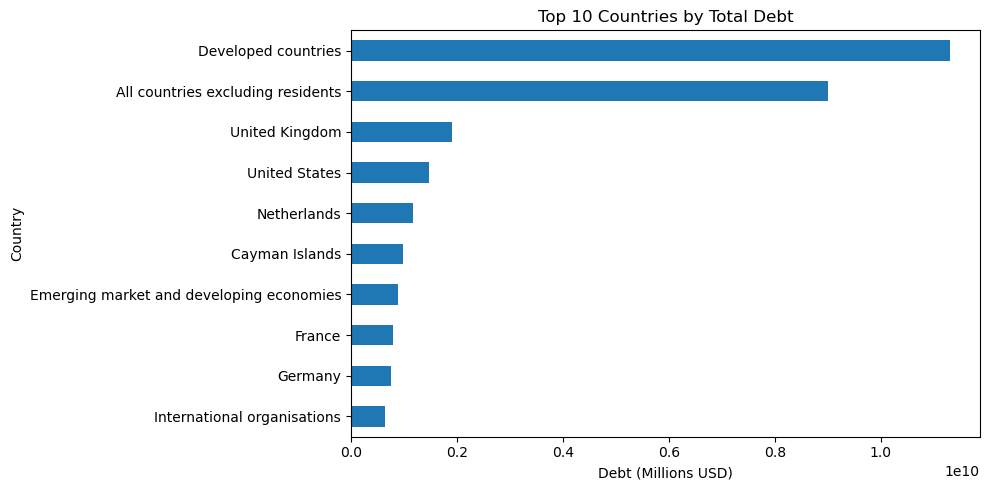

In [19]:
country_total = df.groupby('country')['value_millions_usd'].sum()

top_10 = country_total.sort_values(ascending=False).head(10)

print("Top 10 Countries with Highest Total Debt:")
print(top_10)

top_10.sort_values().plot(kind='barh', figsize=(10, 5))
plt.title("Top 10 Countries by Total Debt")
plt.xlabel("Debt (Millions USD)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

32. How has total debt securities outstanding changed over the years?

Yearly Total Debt:
year
1962    2.160000e+02
1963    2.880000e+02
1964    2.880000e+02
1965    2.880000e+02
1966    1.143500e+04
            ...     
2021    1.736359e+09
2022    1.670929e+09
2023    1.749424e+09
2024    1.858376e+09
2025    2.070411e+09
Name: value_millions_usd, Length: 64, dtype: float64


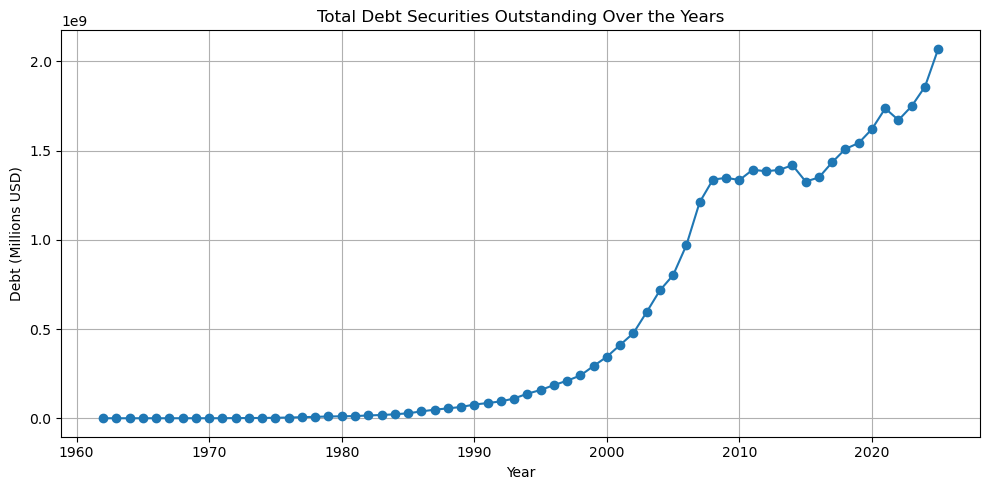

In [20]:
yearly_total = df.groupby('year')['value_millions_usd'].sum()

print("Yearly Total Debt:")
print(yearly_total)

plt.figure(figsize=(10, 5))
plt.plot(yearly_total.index, yearly_total.values, marker='o')
plt.title("Total Debt Securities Outstanding Over the Years")
plt.xlabel("Year")
plt.ylabel("Debt (Millions USD)")
plt.grid(True)
plt.tight_layout()
plt.show()

33. Which countries experienced the largest increase in debt securities outstanding?

Top 10 Largest Debt Increases:
                                country  year    Increase
1409                Developed countries  2007  83246409.0
1427                Developed countries  2025  65973056.0
100   All countries excluding residents  2007  64697376.0
1408                Developed countries  2006  59162417.0
118   All countries excluding residents  2025  53910854.0
99    All countries excluding residents  2006  44980712.0
1410                Developed countries  2008  44832885.0
1406                Developed countries  2004  42733272.0
1405                Developed countries  2003  41555972.0
101   All countries excluding residents  2008  35864453.0


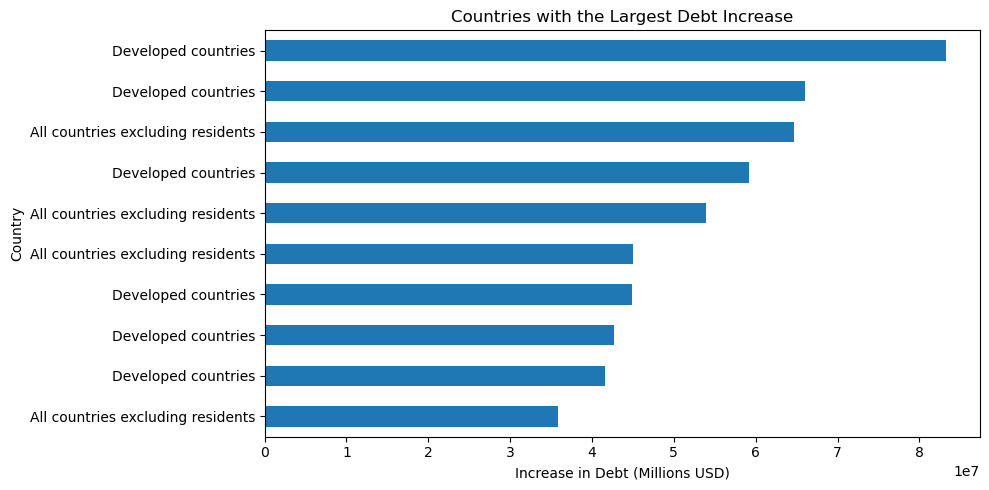

In [21]:
country_year = df.groupby(
    ['country', 'year']
)['value_millions_usd'].sum().reset_index()

country_year = country_year.sort_values(['country', 'year'])

country_year['Increase'] = country_year.groupby(
    'country'
)['value_millions_usd'].diff()

top_increases = country_year.sort_values(
    'Increase', ascending=False
).head(10)

print("Top 10 Largest Debt Increases:")
print(top_increases[['country', 'year', 'Increase']])

top_increases.sort_values('Increase').plot(
    x='country', y='Increase', kind='barh', figsize=(10, 5),
    legend=False
)
plt.title("Countries with the Largest Debt Increase")
plt.xlabel("Increase in Debt (Millions USD)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

34. Which countries have debt securities outstanding above the overall average?

In [22]:
overall_average = df['value_millions_usd'].mean()

country_average = df.groupby(
    'country'
)['value_millions_usd'].mean()

above_average = country_average[
    country_average > overall_average
].sort_values(ascending=False)

print("Overall Average Debt:", round(overall_average, 2))
print("\nCountries Above Overall Average:")
print(above_average)

Overall Average Debt: 59190.84

Countries Above Overall Average:
country
Developed countries                         793355.130981
All countries excluding residents           543782.715123
United Kingdom                              175779.311849
International organisations                 167215.482016
United States                               132680.784629
Cayman Islands                              117351.220399
Netherlands                                 104054.364661
Germany                                      72122.379275
France                                       68814.347701
Emerging market and developing economies     66327.773380
Ireland                                      62057.825151
Name: value_millions_usd, dtype: float64


35. What percentage of total debt securities outstanding is contributed by the top 5 countries?

Top 5 Countries:
country
Developed countries                  1.130848e+10
All countries excluding residents    8.996341e+09
United Kingdom                       1.906327e+09
United States                        1.467449e+09
Netherlands                          1.163640e+09
Name: value_millions_usd, dtype: float64

Total Debt: 34939462631.0 Million USD
Top 5 Countries' Contribution: 71.1 %


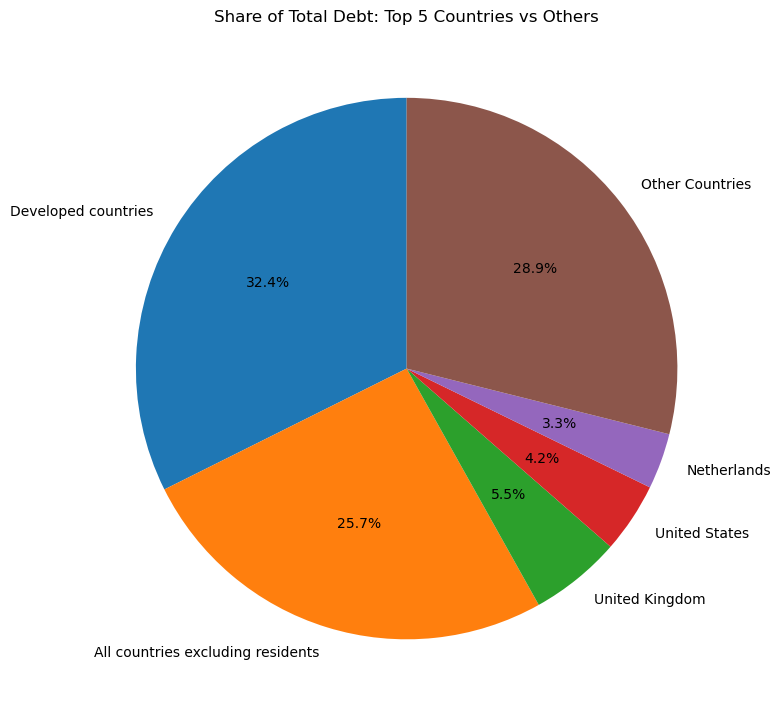

In [23]:
country_total = df.groupby('country')['value_millions_usd'].sum()

top_5 = country_total.sort_values(ascending=False).head(5)

total_debt = country_total.sum()

percentage = (top_5.sum() / total_debt) * 100

print("Top 5 Countries:")
print(top_5)

print("\nTotal Debt:", round(total_debt, 2), "Million USD")
print("Top 5 Countries' Contribution:", round(percentage, 2), "%")

other_countries = total_debt - top_5.sum()

pie_data = pd.concat([
    top_5,
    pd.Series({'Other Countries': other_countries})
])

plt.figure(figsize=(8, 8))
plt.pie(
    pie_data,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Share of Total Debt: Top 5 Countries vs Others")
plt.tight_layout()
plt.show()

### Suggestions & Recommendations

**1. Watch financial-sector funding, not just the total**
Observation: The financial sector is 74% of debt and its net issuance fell by ~471 bn per quarter after the GFC.
Recommendation: Track the financial-sector net issuance as an early-warning indicator of funding stress instead of the aggregate total.

**2. Treat financial centres separately**
Observation: Cayman Islands, Luxembourg, Ireland, Bermuda and others have 10-1000x higher debt per person and an almost purely financial profile.
Recommendation: Analyse them as a separate group (`is_fin_centre`) when comparing countries or building models.

**3. Prepare for uneven refinancing**
Observation: About 78% of gross issuance is refinancing and corporate net issuance turned negative in 2022-23.
Recommendation: Monitor maturity walls and rate levels; issuers relying on short windows are exposed when rates rise.

**4. Focus on the drivers of the recent re-acceleration**
Observation: The market is growing 14.3% YoY, but only 40% of countries are at all-time highs and the large eurozone markets are not.
Recommendation: Identify which issuers (US, UK, Gulf, Cayman) drive the growth before assuming a broad recovery.

**5. Use rates and shares, not counts and means**
Observation: Coverage grew from 14 to 138 countries and market sizes are log-normal.
Recommendation: Use medians, log scales, CAGRs and shares for any cross-era comparison.

### Data Quality Issues & Limitations
- The data covers **international** debt securities by residence of the issuer, not total debt of a country; domestic bond markets are not included.
- Aggregates and nested sectors/maturities can double count if summed carelessly; always filter to one level.
- Country coverage changes over time, so early totals are structurally small.
- Growth columns are unreliable on tiny bases (winsorized in this project).
- Population and area are missing for 7 real countries (name mismatch) and for aggregates.
- Sector components differ from their totals by about 0.1% (rounding / classification).

### Possible next steps
- Predict `growth_regime` or negative net issuance from sector mix, size bucket and shock flags (e.g. Random Forest) using the engineered panel.
- Compare with GDP to convert debt into a debt-to-GDP measure.
- Build a dashboard (Power BI / Tableau) around Q4, Q6, Q12 and Q13.